# Week 2 · Data tools: solutions
Nights 8–14 · 30 November – 6 December 2026

Worked answers for `notebooks/week2_data_tools.ipynb`. Try each exercise yourself first; read a solution only after
20 minutes of being stuck, then close this file and retype it from memory.

Study guide: [Week 2 tab](https://claude.ai/artifact/5MJxvaW9sNxjp7rjmPWuCu#fe0395db-acde).

In [1]:
# Run this cell first (Shift+Enter). It finds your project folder and defines `check`,
# which prints "Correct" when an exercise works.
import math
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = ROOT / "data"


def _same(a, b, tol=1e-6):
    import math as _math
    import numbers as _numbers
    try:
        import numpy as _np
    except ImportError:
        _np = None
    if _np is not None and (isinstance(a, _np.ndarray) or isinstance(b, _np.ndarray)):
        a, b = _np.asarray(a), _np.asarray(b)
        if a.shape != b.shape:
            return False
        if a.dtype.kind in "biuf" and b.dtype.kind in "biuf":
            return bool(_np.allclose(a, b, rtol=1e-5, atol=tol))
        return bool((a == b).all())
    if isinstance(a, bool) or isinstance(b, bool):
        return a == b
    if isinstance(a, _numbers.Number) and isinstance(b, _numbers.Number):
        return _math.isclose(a, b, rel_tol=1e-5, abs_tol=tol)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(_same(x, y, tol) for x, y in zip(a, b))
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(_same(a[k], b[k], tol) for k in a)
    return a == b


def check(label, actual, expected=True, tol=1e-6):
    """Run `actual` (usually a lambda) and print Correct if it equals `expected`."""
    try:
        got = actual() if callable(actual) else actual
    except NotImplementedError:
        print(f"⏳ Not done yet: {label}")
        return
    except Exception as error:  # show the problem without stopping the notebook
        print(f"❌ {label}: your code raised {type(error).__name__}: {error}")
        return
    if _same(got, expected, tol):
        print(f"✅ Correct: {label}")
    else:
        print(f"❌ {label}\n   expected: {expected!r}\n   got:      {got!r}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Ready")

Ready


## Night 8 · Mon 30 Nov: NumPy arrays and vectorized math
Think in whole arrays, not loops: `prices * 1.18` changes every price at once.

In [2]:
# 8.1 Creating arrays
def make_arrays():
    """Return three arrays: 0..9 with np.arange, 5 evenly spaced numbers from 0 to 1 with np.linspace,
    and a 2 x 3 array of zeros with np.zeros."""
    return np.arange(10), np.linspace(0, 1, 5), np.zeros((2, 3))

check("arange", lambda: make_arrays()[0], np.arange(10))
check("linspace", lambda: make_arrays()[1], np.array([0, 0.25, 0.5, 0.75, 1]))
check("zeros has shape (2, 3)", lambda: make_arrays()[2].shape, (2, 3))

✅ Correct: arange
✅ Correct: linspace
✅ Correct: zeros has shape (2, 3)


In [3]:
# 8.2 shape, ndim and size
grades = np.array([[90, 85, 77], [68, 92, 81]])


def describe_array(arr):
    """Return {'shape': ..., 'ndim': ..., 'size': ...} for the array."""
    return {"shape": arr.shape, "ndim": arr.ndim, "size": arr.size}

check("describe_array(grades)", lambda: describe_array(grades), {"shape": (2, 3), "ndim": 2, "size": 6})

✅ Correct: describe_array(grades)


In [4]:
# 8.3 Element-wise math, no loops
prices_inr = np.array([120.0, 250.0, 80.0, 999.0])


def with_gst(prices, rate=0.18):
    """Return the prices with GST added."""
    return prices * (1 + rate)


def discount_if_over(prices, limit=200, discount=0.10):
    """Return the prices, with `discount` taken off anything above `limit`. Hint: np.where."""
    return np.where(prices > limit, prices * (1 - discount), prices)

check("with_gst", lambda: with_gst(np.array([100.0, 200.0])), np.array([118.0, 236.0]))
check("discount_if_over", lambda: discount_if_over(prices_inr), np.array([120.0, 225.0, 80.0, 899.1]))

✅ Correct: with_gst
✅ Correct: discount_if_over


In [5]:
# 8.4 Race: a Python list against a NumPy array
import time

plain_list = list(range(1_000_000))
array = np.arange(1_000_000)

start = time.perf_counter()
squares_list = [n * n for n in plain_list]
list_time = time.perf_counter() - start

start = time.perf_counter()
squares_array = array * array
array_time = time.perf_counter() - start

print(f"list:  {list_time * 1000:.1f} ms")
print(f"array: {array_time * 1000:.1f} ms  ({list_time / array_time:.0f}x faster)")

list:  59.8 ms
array: 5.6 ms  (11x faster)


In [6]:
# 8.5 reshape
def to_grid(values, columns):
    """Reshape a 1-D array into rows of `columns` items. Let NumPy work out the rows with -1."""
    return np.asarray(values).reshape(-1, columns)

check("to_grid(arange(6), 3)", lambda: to_grid(np.arange(6), 3).tolist(), [[0, 1, 2], [3, 4, 5]])
check("to_grid(arange(12), 4).shape", lambda: to_grid(np.arange(12), 4).shape, (3, 4))

✅ Correct: to_grid(arange(6), 3)
✅ Correct: to_grid(arange(12), 4).shape


## Night 9 · Tue 1 Dec: NumPy indexing, broadcasting and axes
`axis=0` runs down the columns, `axis=1` runs across the rows.

In [7]:
# 9.1 Boolean masks
scores = np.array([55, 78, 91, 42, 88, 67])


def passing(scores, cutoff=60):
    """Return only the scores at or above cutoff, using a boolean mask."""
    return scores[scores >= cutoff]


def count_passing(scores, cutoff=60):
    """Return how many scores are at or above cutoff. Hint: True counts as 1 in a sum."""
    return int((scores >= cutoff).sum())

check("passing", lambda: passing(scores), np.array([78, 91, 88, 67]))
check("count_passing", lambda: count_passing(scores), 4)

✅ Correct: passing
✅ Correct: count_passing


In [8]:
# 9.2 Scaling with broadcasting: one number is stretched across the whole array
def min_max_scale(x):
    """Scale x to the range 0..1: (x - min) / (max - min)."""
    return (x - x.min()) / (x.max() - x.min())


def z_score(x):
    """Standardize x: (x - mean) / standard deviation."""
    return (x - x.mean()) / x.std()

check("min_max_scale", lambda: min_max_scale(np.array([10.0, 20.0, 30.0])), np.array([0.0, 0.5, 1.0]))
check("z_score has mean 0 and std 1", lambda: [round(float(z_score(scores).mean()), 6), round(float(z_score(scores).std()), 6)], [0.0, 1.0])

✅ Correct: min_max_scale
✅ Correct: z_score has mean 0 and std 1


In [9]:
# 9.3 Axes. Rows are students; columns are Math, Science, English.
marks = np.array([[90, 72, 85], [60, 88, 79], [75, 95, 70]])


def subject_means(marks):
    """Return the mean of each column (subject)."""
    return marks.mean(axis=0)


def student_totals(marks):
    """Return the total of each row (student)."""
    return marks.sum(axis=1)

check("subject_means", lambda: subject_means(marks), np.array([75.0, 85.0, 78.0]))
check("student_totals", lambda: student_totals(marks), np.array([247, 227, 240]))

✅ Correct: subject_means
✅ Correct: student_totals


In [10]:
# 9.4 argmax
def best_subject_per_student(marks, subjects=("Math", "Science", "English")):
    """Return each student's best subject name. Hint: marks.argmax(axis=1)."""
    return [subjects[i] for i in marks.argmax(axis=1)]

check("best_subject_per_student", lambda: best_subject_per_student(marks), ["Math", "Science", "Science"])

✅ Correct: best_subject_per_student


In [11]:
# 9.5 Randomness you can repeat
def roll_dice(n_rolls, seed=42):
    """Roll two dice n_rolls times using rng = np.random.default_rng(seed).
    Return the share of rolls where the two dice add up to 7."""
    rng = np.random.default_rng(seed)
    dice = rng.integers(1, 7, size=(n_rolls, 2))
    return float((dice.sum(axis=1) == 7).mean())

check("close to 1/6 after 100,000 rolls", lambda: abs(roll_dice(100_000) - 1 / 6) < 0.01, True)
check("the same seed gives the same answer", lambda: roll_dice(1000) == roll_dice(1000), True)

✅ Correct: close to 1/6 after 100,000 rolls
✅ Correct: the same seed gives the same answer


## Night 10 · Wed 2 Dec: pandas DataFrames
A DataFrame is a table and each column is a Series. `loc` selects by label, `iloc` by position.
The data: 344 penguins from three islands in Antarctica (the Palmer Penguins dataset).

In [12]:
penguins = pd.read_csv(DATA / "penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [13]:
penguins.info()
penguins.describe()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [14]:
# 10.1 Selecting and filtering
def n_rows_and_columns(df):
    return df.shape


def species_list(df):
    """Return the sorted list of unique species."""
    return sorted(df["species"].unique())


def heavy_penguins(df, grams=5000):
    """Return the rows where body_mass_g is above `grams`."""
    return df[df["body_mass_g"] > grams]


def first_row_island(df):
    """Use iloc to return the island of the first row."""
    return df.iloc[0]["island"]


def bill_columns(df):
    """Return only the columns bill_length_mm and bill_depth_mm."""
    return df[["bill_length_mm", "bill_depth_mm"]]

check("shape", lambda: n_rows_and_columns(penguins), (344, 7))
check("species_list", lambda: species_list(penguins), ["Adelie", "Chinstrap", "Gentoo"])
check("61 penguins weigh over 5 kg", lambda: len(heavy_penguins(penguins)), 61)
check("first_row_island", lambda: first_row_island(penguins), "Torgersen")
check("bill_columns", lambda: bill_columns(penguins).columns.tolist(), ["bill_length_mm", "bill_depth_mm"])

✅ Correct: shape
✅ Correct: species_list
✅ Correct: 61 penguins weigh over 5 kg
✅ Correct: first_row_island
✅ Correct: bill_columns


In [15]:
# 10.2 Missing values and loc
def missing_per_column(df):
    """Return a dict: column name -> number of missing values."""
    return df.isna().sum().to_dict()


def dream_species_counts(df):
    """Use loc to count the species on Dream island. Return a dict: species -> count."""
    return df.loc[df["island"] == "Dream", "species"].value_counts().to_dict()

check(
    "missing_per_column",
    lambda: missing_per_column(penguins),
    {"species": 0, "island": 0, "bill_length_mm": 2, "bill_depth_mm": 2, "flipper_length_mm": 2, "body_mass_g": 2, "sex": 11},
)
check("dream_species_counts", lambda: dream_species_counts(penguins), {"Chinstrap": 68, "Adelie": 56})

✅ Correct: missing_per_column
✅ Correct: dream_species_counts


## Night 11 · Thu 3 Dec: Cleaning, grouping and new columns
`groupby` is split, apply, combine, like SQL's GROUP BY. Return new DataFrames instead of changing the original.

In [16]:
# 11.1 Missing values
def drop_missing(df):
    """Return a copy without the rows that have any missing value."""
    return df.dropna()


def fill_sex(df):
    """Return a copy where missing values in the sex column become 'Unknown'."""
    return df.assign(sex=df["sex"].fillna("Unknown"))

check("drop_missing shape", lambda: drop_missing(penguins).shape, (333, 7))
check("11 penguins have sex 'Unknown'", lambda: int((fill_sex(penguins)["sex"] == "Unknown").sum()), 11)
check("the original still has its missing values", lambda: int(penguins["sex"].isna().sum()), 11)

✅ Correct: drop_missing shape
✅ Correct: 11 penguins have sex 'Unknown'
✅ Correct: the original still has its missing values


In [17]:
# 11.2 groupby and value_counts
def mean_mass_by_species(df):
    """Return a dict: species -> mean body mass in grams, rounded to 1 decimal."""
    return df.groupby("species")["body_mass_g"].mean().round(1).to_dict()


def count_by_island(df):
    """Return a dict: island -> number of penguins."""
    return df["island"].value_counts().to_dict()

check("mean_mass_by_species", lambda: mean_mass_by_species(penguins), {"Adelie": 3700.7, "Chinstrap": 3733.1, "Gentoo": 5076.0})
check("count_by_island", lambda: count_by_island(penguins), {"Biscoe": 168, "Dream": 124, "Torgersen": 52})

✅ Correct: mean_mass_by_species
✅ Correct: count_by_island


In [18]:
# 11.3 New columns and sorting
def add_bill_ratio(df):
    """Return a copy with a new column bill_ratio = bill_length_mm / bill_depth_mm."""
    return df.assign(bill_ratio=df["bill_length_mm"] / df["bill_depth_mm"])


def heaviest_five(df):
    """Return the 5 heaviest penguins, heaviest first."""
    return df.sort_values("body_mass_g", ascending=False).head(5)

check("mean bill_ratio", lambda: round(float(add_bill_ratio(penguins)["bill_ratio"].mean()), 3), 2.606)
check("the original has no bill_ratio column", lambda: "bill_ratio" in penguins.columns, False)
check("heaviest_five", lambda: heaviest_five(penguins)["body_mass_g"].tolist(), [6300.0, 6050.0, 6000.0, 6000.0, 5950.0])

✅ Correct: mean bill_ratio
✅ Correct: the original has no bill_ratio column
✅ Correct: heaviest_five


In [19]:
# 11.4 Merging two tables
species_info = pd.DataFrame({
    "species": ["Adelie", "Chinstrap", "Gentoo"],
    "scientific_name": ["Pygoscelis adeliae", "Pygoscelis antarcticus", "Pygoscelis papua"],
})


def add_scientific_name(df, info):
    """Left-merge `info` into df on the species column."""
    return df.merge(info, on="species", how="left")

check("merged shape", lambda: add_scientific_name(penguins, species_info).shape, (344, 8))
check("every row got a name", lambda: int(add_scientific_name(penguins, species_info)["scientific_name"].isna().sum()), 0)

✅ Correct: merged shape
✅ Correct: every row got a name


## Night 12 · Fri 4 Dec: Charts with Matplotlib and seaborn
Histograms show distributions, scatter plots show relationships, bar charts compare groups. Always label your axes.
These cells have no checks: you check them by looking.

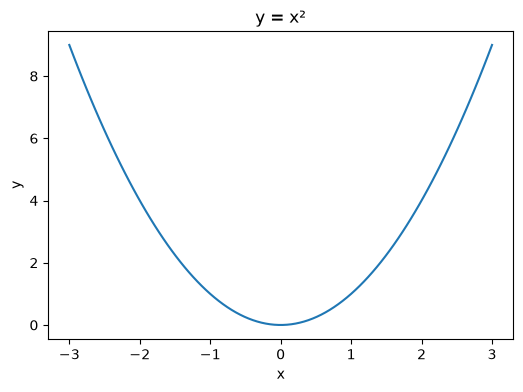

In [20]:
# 12.1 Line plot of y = x² from -3 to 3
x = np.linspace(-3, 3, 100)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x, x ** 2)
ax.set_title("y = x²")
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()

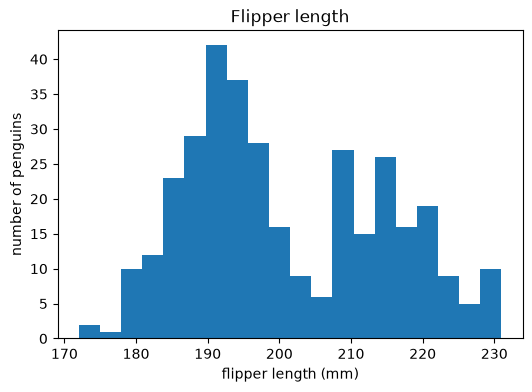

In [21]:
# 12.2 Histogram of flipper length, 20 bins
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(penguins["flipper_length_mm"].dropna(), bins=20)
ax.set_title("Flipper length")
ax.set_xlabel("flipper length (mm)")
ax.set_ylabel("number of penguins")
plt.show()

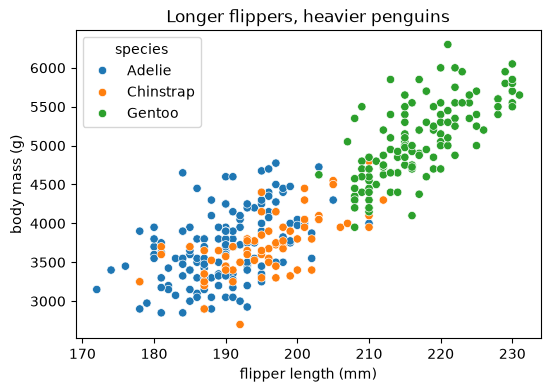

In [22]:
# 12.3 Scatter plot: flipper length against body mass, coloured by species
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g", hue="species", ax=ax)
ax.set_title("Longer flippers, heavier penguins")
ax.set_xlabel("flipper length (mm)")
ax.set_ylabel("body mass (g)")
plt.show()

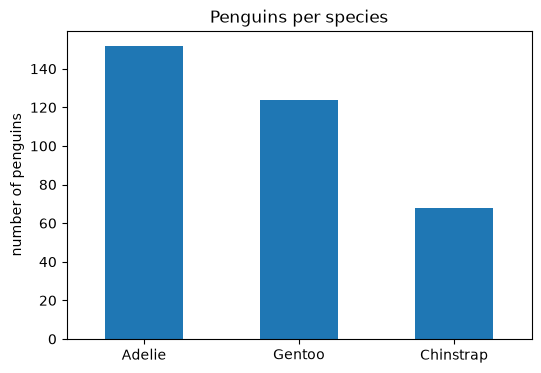

In [23]:
# 12.4 Bar chart: number of penguins per species
fig, ax = plt.subplots(figsize=(6, 4))
penguins["species"].value_counts().plot.bar(ax=ax, rot=0)
ax.set_title("Penguins per species")
ax.set_xlabel("")
ax.set_ylabel("number of penguins")
plt.show()

In [24]:
# 12.5 Save a chart as a PNG file
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g", hue="species", ax=ax)
ax.set_title("Longer flippers, heavier penguins")
fig.savefig(FIGURES / "flipper_vs_mass.png", dpi=150, bbox_inches="tight")
plt.close(fig)

check("figures/flipper_vs_mass.png exists", lambda: (FIGURES / "flipper_vs_mass.png").exists(), True)

✅ Correct: figures/flipper_vs_mass.png exists


## Night 13 · Sat 5 Dec: Exploring a dataset (EDA)
The data: 244 restaurant bills with the tip, day, time and table size. Work through the checklist in the
Week 2 tab, then write three findings at the bottom.

In [25]:
tips = pd.read_csv(DATA / "tips.csv")
print(tips.shape)
print(tips.dtypes)
tips.isna().sum()

(244, 7)
total_bill    float64
tip           float64
sex               str
smoker            str
day               str
time              str
size            int64
dtype: object


total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [26]:
# 13.1 A new column and a grouped mean
def add_tip_pct(df):
    """Return a copy with tip_pct = tip / total_bill * 100."""
    return df.assign(tip_pct=df["tip"] / df["total_bill"] * 100)


def mean_tip_pct_by(df, column):
    """Return a dict: group value -> mean tip_pct rounded to 1 decimal, grouped by `column`."""
    return df.groupby(column)["tip_pct"].mean().round(1).to_dict()

check("average tip is about 16%", lambda: round(float(add_tip_pct(tips)["tip_pct"].mean()), 2), 16.08)
check("tip % by day", lambda: mean_tip_pct_by(add_tip_pct(tips), "day"), {"Fri": 17.0, "Sat": 15.3, "Sun": 16.7, "Thur": 16.1})

✅ Correct: average tip is about 16%
✅ Correct: tip % by day


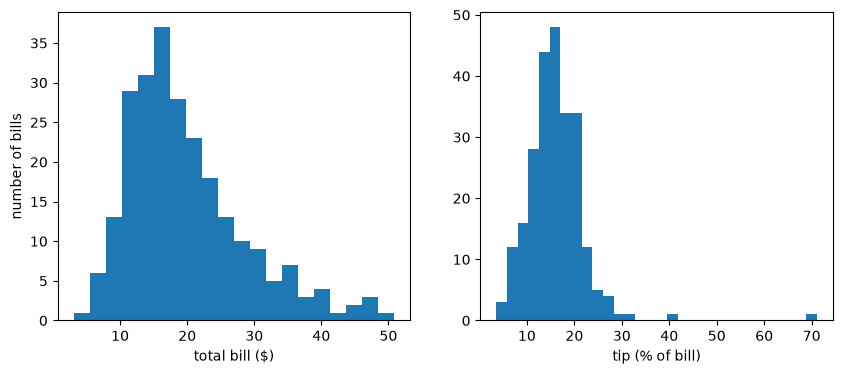

In [27]:
# 13.2 Distributions: histograms of total_bill and tip_pct, side by side
tips_pct = add_tip_pct(tips)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
left.hist(tips_pct["total_bill"], bins=20)
left.set_xlabel("total bill ($)")
left.set_ylabel("number of bills")
right.hist(tips_pct["tip_pct"], bins=30)
right.set_xlabel("tip (% of bill)")
plt.show()

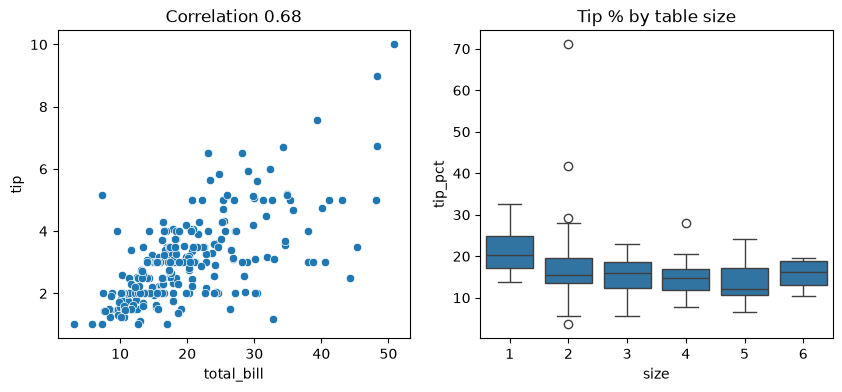

In [28]:
# 13.3 Relationships and outliers: tip against bill, and tip % by table size
tips_pct = add_tip_pct(tips)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
sns.scatterplot(data=tips_pct, x="total_bill", y="tip", ax=left)
left.set_title(f"Correlation {tips_pct['total_bill'].corr(tips_pct['tip']):.2f}")
sns.boxplot(data=tips_pct, x="size", y="tip_pct", ax=right)
right.set_title("Tip % by table size")
plt.show()

### 13.4 Three findings, in plain words
1. People tip about 16% on average (median 15.5%), and bigger bills get bigger tips: bill and tip have a correlation of 0.68.
2. Bigger bills get a *smaller percentage*: bill and tip % have a correlation of −0.34, and tables of one tip 21.7%
   on average against 14.1–14.6% for tables of four or five.
3. One table tipped 71% of the bill. An outlier like that pulls averages up, so check it before trusting a group mean.
   Saturday has the most bills (87) but the lowest average tip (15.3%).

## Night 14 · Sun 6 Dec: Review and project: the Titanic data story
The data: 891 Titanic passengers and whether they survived. Answer the questions, make four charts, then write
five insights in plain words.

In [29]:
titanic = pd.read_csv(DATA / "titanic.csv")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [30]:
# 14.1 Survival rates
def survival_rate(df):
    """Return the percentage of passengers who survived, rounded to 1 decimal."""
    return round(float(df["survived"].mean() * 100), 1)


def survival_by(df, column):
    """Return a dict: group -> survival percentage rounded to 1 decimal.
    Use df.groupby(column, observed=True) so it also works on category columns."""
    return (df.groupby(column, observed=True)["survived"].mean() * 100).round(1).to_dict()


def add_age_group(df):
    """Return a copy with age_group: 'child' under 13, 'teen' 13-17, 'adult' 18-59, 'senior' 60+.
    Hint: pd.cut(df["age"], bins=[0, 13, 18, 60, 120], right=False, labels=[...]). Missing ages stay missing."""
    groups = pd.cut(df["age"], bins=[0, 13, 18, 60, 120], right=False, labels=["child", "teen", "adult", "senior"])
    return df.assign(age_group=groups)

check("overall survival", lambda: survival_rate(titanic), 38.4)
check("by sex", lambda: survival_by(titanic, "sex"), {"female": 74.2, "male": 18.9})
check("by class", lambda: survival_by(titanic, "pclass"), {1: 63.0, 2: 47.3, 3: 24.2})
check(
    "by age group",
    lambda: survival_by(add_age_group(titanic), "age_group"),
    {"child": 58.0, "teen": 47.7, "adult": 38.6, "senior": 26.9},
)

✅ Correct: overall survival
✅ Correct: by sex
✅ Correct: by class
✅ Correct: by age group


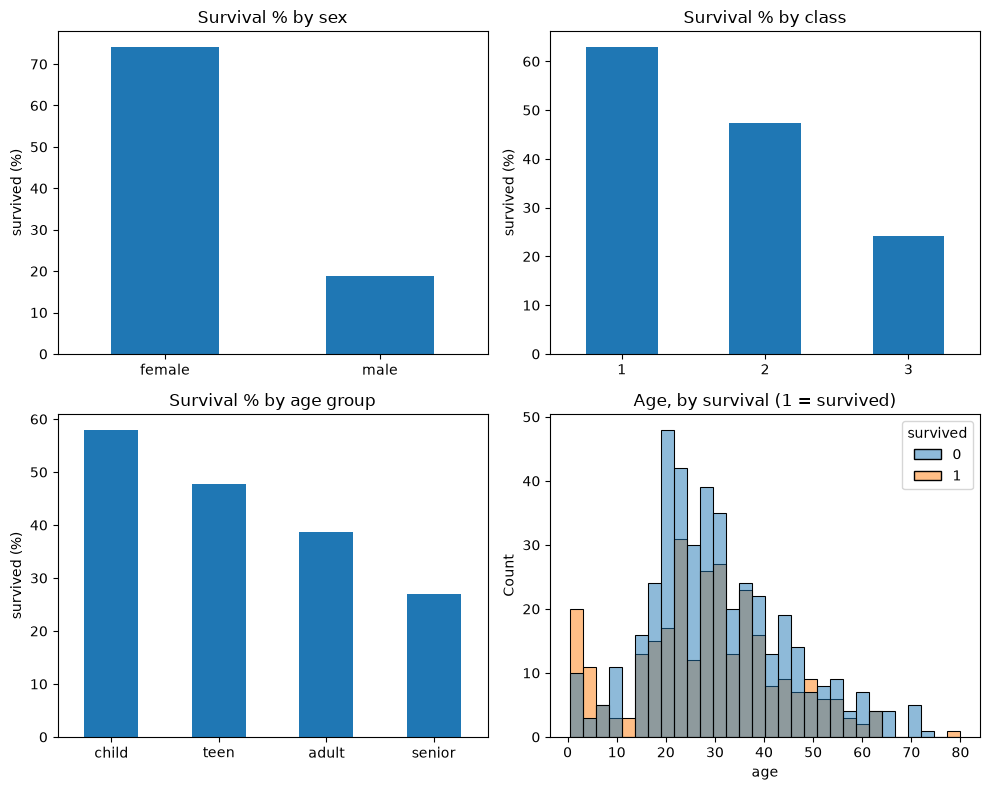

In [31]:
# 14.2 Four charts: survival % by sex, by class, by age group, and the age distribution by survival
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
pd.Series(survival_by(titanic, "sex")).plot.bar(ax=axes[0, 0], rot=0, title="Survival % by sex")
pd.Series(survival_by(titanic, "pclass")).plot.bar(ax=axes[0, 1], rot=0, title="Survival % by class")
pd.Series(survival_by(add_age_group(titanic), "age_group")).plot.bar(ax=axes[1, 0], rot=0, title="Survival % by age group")
sns.histplot(data=titanic, x="age", hue="survived", bins=30, ax=axes[1, 1])
axes[1, 1].set_title("Age, by survival (1 = survived)")
for ax in axes.flat[:3]:
    ax.set_ylabel("survived (%)")
plt.tight_layout()
plt.show()

### 14.3 Five insights, in plain words
1. Only 38.4% of the 891 passengers in this dataset survived.
2. Sex mattered most: 74.2% of women survived against 18.9% of men.
3. Class mattered too: 63.0% survived in first class, 47.3% in second and 24.2% in third.
4. Children under 13 survived more often (58.0%) than adults aged 18–59 (38.6%) or people 60 and over (26.9%).
   177 passengers have no age, so the age groups leave them out.
5. Sex and class combine: 96.8% of women in first class survived, but only 13.5% of men in third class.